In [ ]:
!pip install pyspark

In [ ]:
import pandas as pd

data = {
    "student_id": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "name": [
        "Megha", "Nithya", "Preethi", "Anil", "Sneha",
        "Lokesh", "Rohith", "Rahul", "Pavani", "Ganesh"
    ],
    "department": [
        "CSE", "ECE", "CSE", "MECH", "ECE",
        "CSE", "IT", "MECH", "IT", "ECE"
    ],
    "marks": [88, 72, 94, 56, 81, 45, 91, 67, 78, 85],
    "gpa": [8.8, 7.2, 9.4, 5.6, 8.1, 4.5, 9.1, 6.7, 7.8, 8.5],
    "attendance": [95, 82, 98, 68, 91, 60, 96, 76, 88, 92]
}

pdf = pd.DataFrame(data)
pdf.to_csv("/content/students.csv", index=False)

print("Student dataset created successfully!")
display(pdf)

Student dataset created successfully!


,student_id,name,department,marks,gpa,attendance
0,101,Megha,CSE,88,8.8,95
1,102,Nithya,ECE,72,7.2,82
2,103,Preethi,CSE,94,9.4,98
3,104,Anil,MECH,56,5.6,68
4,105,Sneha,ECE,81,8.1,91
5,106,Lokesh,CSE,45,4.5,60
6,107,Rohith,IT,91,9.1,96
7,108,Rahul,MECH,67,6.7,76
8,109,Pavani,IT,78,7.8,88
9,110,Ganesh,ECE,85,8.5,92


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("StudentBigDataAnalytics")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/content/students.csv")
)

print("Dataset loaded successfully!")
df.show()
df.printSchema()

Dataset loaded successfully!
+----------+-------+----------+-----+---+----------+
|student_id|   name|department|marks|gpa|attendance|
+----------+-------+----------+-----+---+----------+
|       101|  Megha|       CSE|   88|8.8|        95|
|       102| Nithya|       ECE|   72|7.2|        82|
|       103|Preethi|       CSE|   94|9.4|        98|
|       104|   Anil|      MECH|   56|5.6|        68|
|       105|  Sneha|       ECE|   81|8.1|        91|
|       106| Lokesh|       CSE|   45|4.5|        60|
|       107| Rohith|        IT|   91|9.1|        96|
|       108|  Rahul|      MECH|   67|6.7|        76|
|       109| Pavani|        IT|   78|7.8|        88|
|       110| Ganesh|       ECE|   85|8.5|        92|
+----------+-------+----------+-----+---+----------+

root
 |-- student_id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- department: string (nullable = true)
 |-- marks: integer (nullable = true)
 |-- gpa: double (nullable = true)
 |-- attendance: integer (nul

In [ ]:
clean_df = (
    df.dropDuplicates(["student_id"])
    .filter(
        F.col("student_id").isNotNull()
        & F.col("department").isNotNull()
        & F.col("marks").between(0, 100)
        & F.col("gpa").between(0, 10)
        & F.col("attendance").between(0, 100)
    )
)

clean_df = (
    clean_df
    .withColumn(
        "result",
        F.when(F.col("marks") >= 40, "PASS")
         .otherwise("FAIL")
    )
    .withColumn(
        "performance",
        F.when(F.col("marks") >= 90, "Excellent")
         .when(F.col("marks") >= 75, "Very Good")
         .when(F.col("marks") >= 60, "Good")
         .otherwise("Needs Improvement")
    )
)

clean_df.show()

+----------+-------+----------+-----+---+----------+------+-----------------+
|student_id|   name|department|marks|gpa|attendance|result|      performance|
+----------+-------+----------+-----+---+----------+------+-----------------+
|       101|  Megha|       CSE|   88|8.8|        95|  PASS|        Very Good|
|       102| Nithya|       ECE|   72|7.2|        82|  PASS|             Good|
|       103|Preethi|       CSE|   94|9.4|        98|  PASS|        Excellent|
|       104|   Anil|      MECH|   56|5.6|        68|  PASS|Needs Improvement|
|       105|  Sneha|       ECE|   81|8.1|        91|  PASS|        Very Good|
|       106| Lokesh|       CSE|   45|4.5|        60|  PASS|Needs Improvement|
|       107| Rohith|        IT|   91|9.1|        96|  PASS|        Excellent|
|       108|  Rahul|      MECH|   67|6.7|        76|  PASS|             Good|
|       109| Pavani|        IT|   78|7.8|        88|  PASS|        Very Good|
|       110| Ganesh|       ECE|   85|8.5|        92|  PASS|     

In [ ]:
overall = clean_df.agg(
    F.count("*").alias("Total_Students"),
    F.round(F.avg("marks"), 2).alias("Average_Marks"),
    F.round(F.avg("gpa"), 2).alias("Average_GPA"),
    F.round(F.avg("attendance"), 2).alias("Average_Attendance"),
    F.round(
        F.avg(
            F.when(F.col("result") == "PASS", 100.0)
             .otherwise(0.0)
        ), 2
    ).alias("Pass_Percentage")
)

overall.show(truncate=False)

+--------------+-------------+-----------+------------------+---------------+
|Total_Students|Average_Marks|Average_GPA|Average_Attendance|Pass_Percentage|
+--------------+-------------+-----------+------------------+---------------+
|10            |75.7         |7.57       |84.6              |100.0          |
+--------------+-------------+-----------+------------------+---------------+



In [ ]:
department_report = (
    clean_df.groupBy("department")
    .agg(
        F.count("*").alias("Total_Students"),
        F.round(F.avg("marks"), 2).alias("Average_Marks"),
        F.round(F.avg("gpa"), 2).alias("Average_GPA"),
        F.round(F.avg("attendance"), 2).alias("Average_Attendance"),
        F.sum(
            F.when(F.col("result") == "PASS", 1).otherwise(0)
        ).alias("Passed_Students")
    )
    .orderBy(F.desc("Average_Marks"))
)

department_report.show()

+----------+--------------+-------------+-----------+------------------+---------------+
|department|Total_Students|Average_Marks|Average_GPA|Average_Attendance|Passed_Students|
+----------+--------------+-------------+-----------+------------------+---------------+
|        IT|             2|         84.5|       8.45|              92.0|              2|
|       ECE|             3|        79.33|       7.93|             88.33|              3|
|       CSE|             3|        75.67|       7.57|             84.33|              3|
|      MECH|             2|         61.5|       6.15|              72.0|              2|
+----------+--------------+-------------+-----------+------------------+---------------+



In [ ]:
top_students = (
    clean_df.orderBy(
        F.desc("marks"),
        F.desc("gpa")
    )
    .limit(5)
)

top_students.show(truncate=False)

+----------+-------+----------+-----+---+----------+------+-----------+
|student_id|name   |department|marks|gpa|attendance|result|performance|
+----------+-------+----------+-----+---+----------+------+-----------+
|103       |Preethi|CSE       |94   |9.4|98        |PASS  |Excellent  |
|107       |Rohith |IT        |91   |9.1|96        |PASS  |Excellent  |
|101       |Megha  |CSE       |88   |8.8|95        |PASS  |Very Good  |
|110       |Ganesh |ECE       |85   |8.5|92        |PASS  |Very Good  |
|105       |Sneha  |ECE       |81   |8.1|91        |PASS  |Very Good  |
+----------+-------+----------+-----+---+----------+------+-----------+



In [ ]:
low_attendance = (
    clean_df.filter(F.col("attendance") < 75)
    .select("student_id", "name", "department", "attendance", "marks")
    .orderBy("attendance")
)

low_attendance.show()

+----------+------+----------+----------+-----+
|student_id|  name|department|attendance|marks|
+----------+------+----------+----------+-----+
|       106|Lokesh|       CSE|        60|   45|
|       104|  Anil|      MECH|        68|   56|
+----------+------+----------+----------+-----+



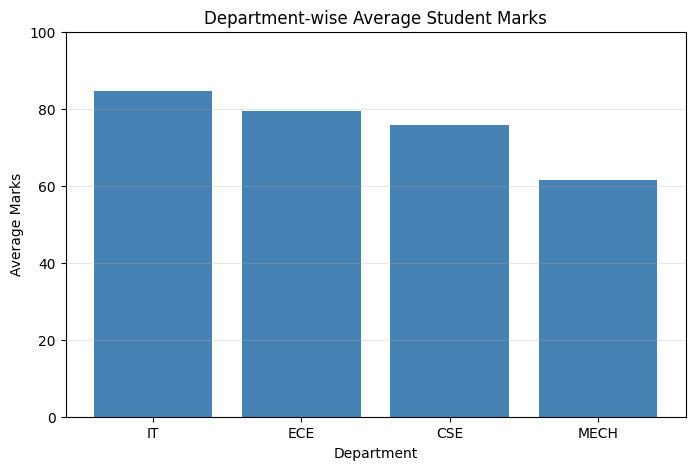

In [ ]:
import matplotlib.pyplot as plt

chart_data = department_report.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(
    chart_data["department"],
    chart_data["Average_Marks"],
    color="steelblue"
)

plt.title("Department-wise Average Student Marks")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
import os
import shutil
from google.colab import files

output_dir = "/content/student_reports"
os.makedirs(output_dir, exist_ok=True)

reports = {
    "overall_report": overall,
    "department_report": department_report,
    "top_students": top_students,
    "low_attendance": low_attendance
}

for name, report in reports.items():
    report.toPandas().to_csv(
        f"{output_dir}/{name}.csv",
        index=False
    )

shutil.make_archive(
    "/content/student_reports",
    "zip",
    output_dir
)

files.download("/content/student_reports.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>